# Stage 4 | The Paired Evaluation, Now on Test-Tube Grasp

**How do we carry [Notebook 3](03_latent_pickcube_policy_evaluation.ipynb)'s paired evaluation onto MuJoCo test-tube grasp?**

Three pieces are required. Prepare a frozen controller for the tube task. Train a task-specific world model that can keep that controller closed-loop on predicted state. From the same starts, compare the simulator's judgment with the world model's judgment of that same controller.

The controller is the state-based student learned from the 80-demo ACT teacher's action targets, plus the fixed lift rule. Sections 1–3 show the controller, the tube model, and the two loops. On seeds 10290200–10290299 the result is **90/100** actual MuJoCo successes, **95/100** model success calls, and **87/100** matching labels. The 13 disagreements are 9 imagined-only lifts and 4 missed actual lifts. **95 is neither a higher policy score nor a more accurate evaluation.**

Follow the pictures, then watch four paired cases. All media and results are saved; these cells only display them, redraw curves, and check consistency.


## 1. Where did the controller and model come from?

**Read the four steps:** imitation, simulator verification, dynamics learning, then paired evaluation. The first three were completed earlier; **step 4 is this notebook**.

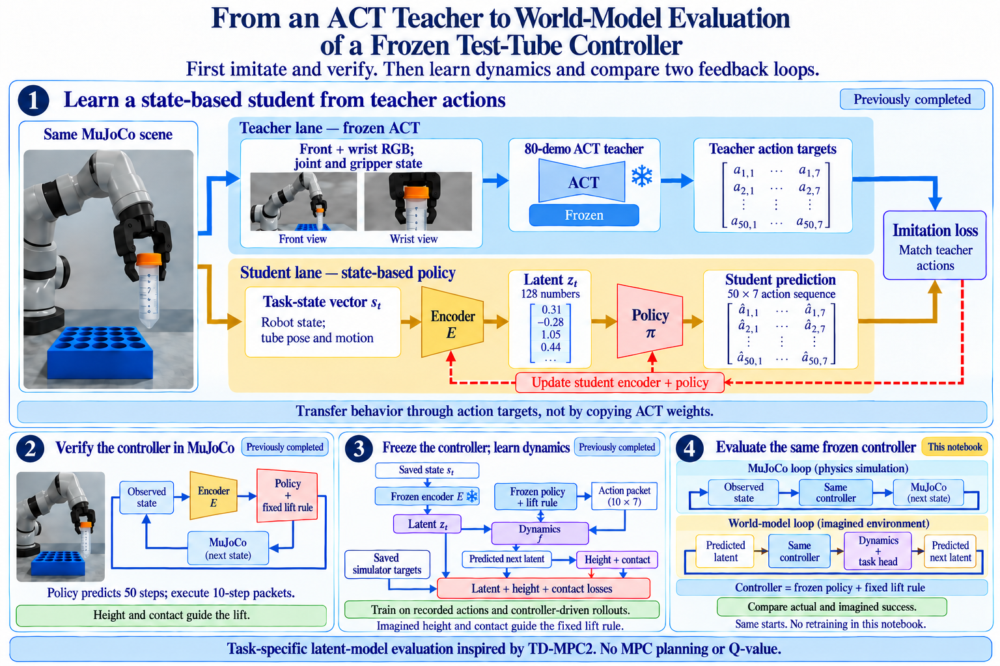

This continues Stage 3's comparison with a task-specific tube model. It does not load the PickCube TD-MPC2 weights, and it does not rerun Stage 2's native image loop.

When this stage was carried out, public code for finetuning the official TD-MPC2 checkpoint on this task was not available. The model here is a tube-specific latent model inspired by TD-MPC2. It predicts the next latent state for the frozen controller and reads out tube height and contact for the lift rule and the success check. It is not a finetune of the official pretrained TD-MPC2 weights. No MPC planning or Q-value is used.

## 2. How does the model evaluate the controller?

**Read left to right:** encode the starting state, repeat controller-and-dynamics steps, then judge the predicted height and contact. The model predicts internal states, not future camera images.

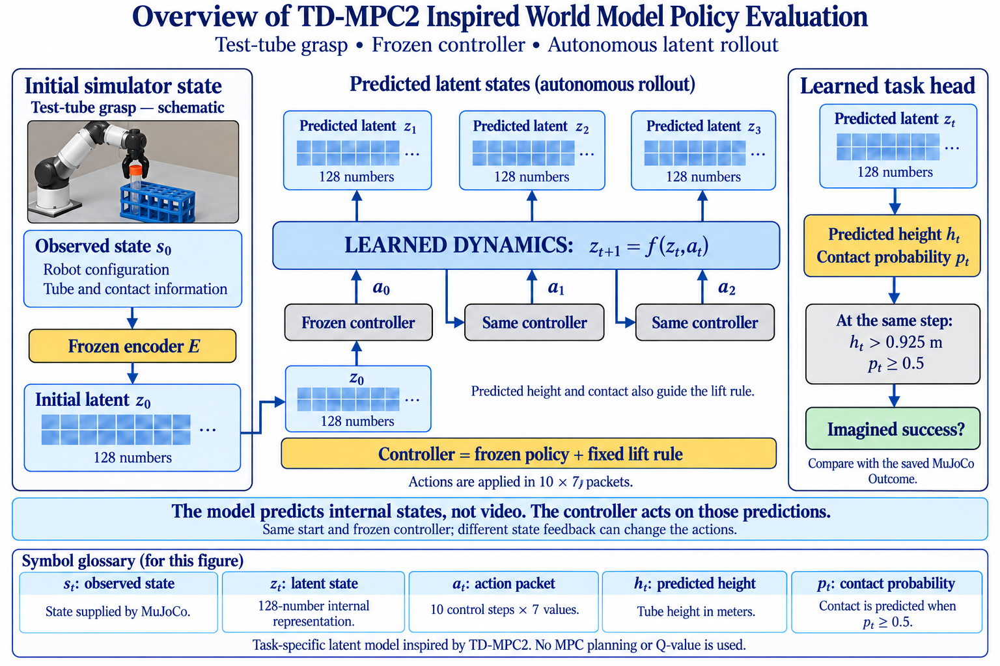

Success requires height **> 0.925 m** and contact **at the same step**; model contact is true when its probability is **at least 0.5**. No MPC or Q-value is used.

<details>
<summary>Optional: the three earlier dynamics lessons</summary>

These are earlier results, not training performed by this notebook. The roughly one-second model called 7/100 starts successful and agreed on 11/100; ten-second imagination gave 79/100 success calls and 79/100 agreements. The selected closed-loop model gives 95/100 and 87/100.

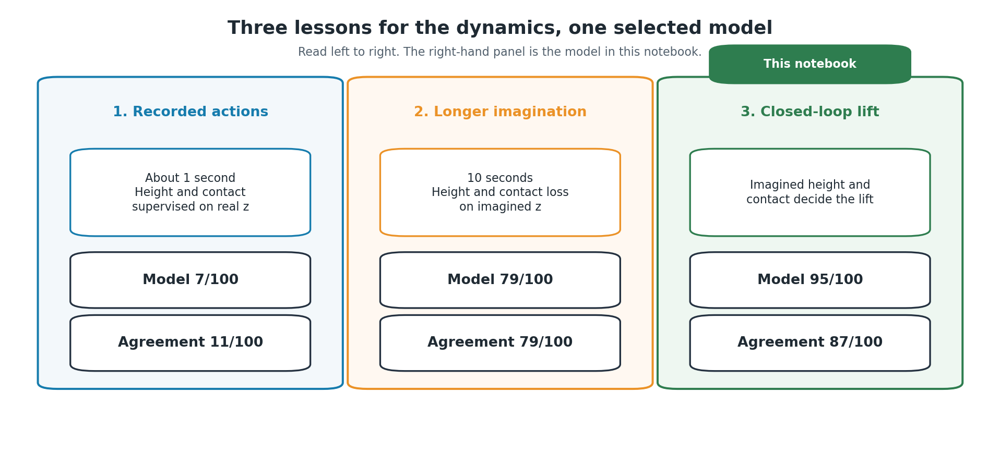

The model used here is **repair v2 at step 8000**, selected on the development set with **37/40** agreements. Seeds **10290200-10290299** were not used to select it.

</details>

## 3. Same starting state, same controller, two feedback loops

**Follow the return arrows:** MuJoCo supplies the next observed state; the model supplies the next imagined state.

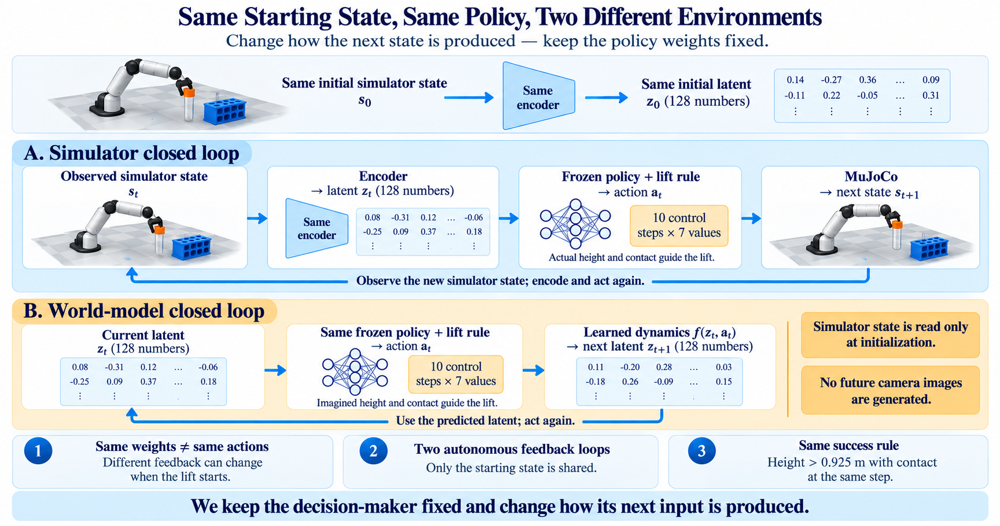

**The weights are the same, but MuJoCo feeds back the actual next state while the model feeds back imagined height and contact, so the lift rule can start at different times.**

### Watch four paired cases

Each case follows the same path: **MuJoCo video → six moments → measured curves → model animation → one takeaway.** Each seed is the smallest in its outcome group.

In model animations, **orange is predicted; dashed blue is the simulator reference**, added afterward. The center shows latent values; the right shows actions.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video, HTML

ROOT = Path.cwd().resolve()
candidates = [
    ROOT / "media" / "stage4",
    ROOT / "media" / "tube_closed_loop",
    ROOT / "teaching" / "media" / "tube_closed_loop",
]
PACK = next(path for path in candidates if (path / "summary.json").exists())
summary = json.loads((PACK / "summary.json").read_text(encoding="utf-8"))
rows = summary["rows"]
print(f"Loaded {len(rows)} saved pairs. No simulation or model inference is run.")

def show_case(seed, title):
    episode = np.load(PACK / "cases" / f"{seed}.npz")
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 5.6), sharex="col", constrained_layout=True)
    series = [
        (0, episode["sim_time"], episode["sim_height"], episode["sim_contact"], "Simulator", "#167cad", "Contact (0 or 1)"),
        (1, episode["model_time"], episode["model_height"], episode["model_contact"], "World model", "#eb9227", "Contact probability"),
    ]
    for col, time, height, contact, name, color, contact_name in series:
        axes[0, col].plot(time, height, color=color)
        axes[0, col].axhline(0.8847, color="#52606d", ls="--", lw=1, label="Lift may start, 0.8847 m")
        axes[0, col].axhline(0.925, color="#b42318", ls=":", lw=1, label="Official height, 0.925 m")
        axes[0, col].set_title(name)
        axes[0, col].set_ylabel("Height (m)")
        axes[0, col].set_ylim(0.75, 1.02)
        axes[0, col].legend(fontsize=8, loc="lower right")
        axes[1, col].plot(time, contact, color=color)
        axes[1, col].axhline(0.5, color="#52606d", ls="--", lw=1, label="Contact threshold 0.5")
        axes[1, col].set_ylabel(contact_name)
        axes[1, col].set_xlabel("Time (s)")
        axes[1, col].set_ylim(-0.05, 1.05)
        axes[1, col].legend(fontsize=8, loc="lower right")
    fig.suptitle(title)
    plt.show()
    return episode

Loaded 100 saved pairs. No simulation or model inference is run.


### A. MuJoCo Success, World Model Predicts Success

Seed **10290200** · **Watch:** Watch the tube lift out of the rack.

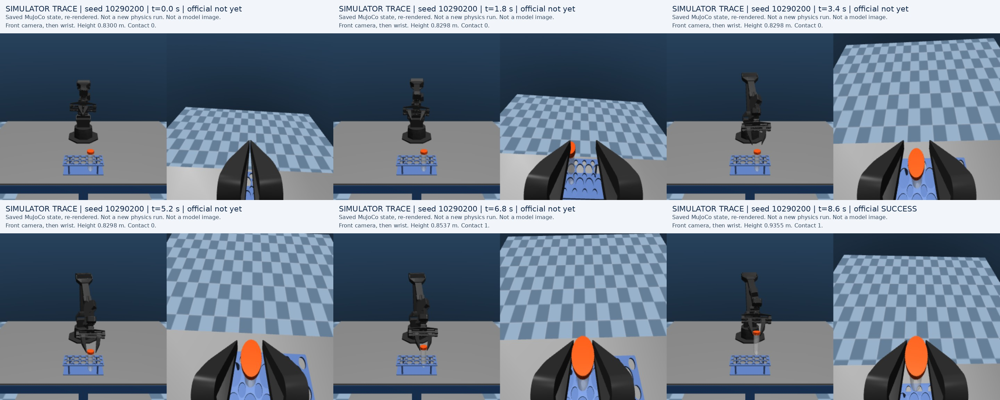

In [2]:
display(Video(str(PACK / "sim_success.mp4"), embed=True, width=1000))
display(Image(filename=str(PACK / "sim_success_timeline.jpg"), width=1100))

**Measure:** Check height and contact together; the dashed lower height line only marks where lifting may begin.

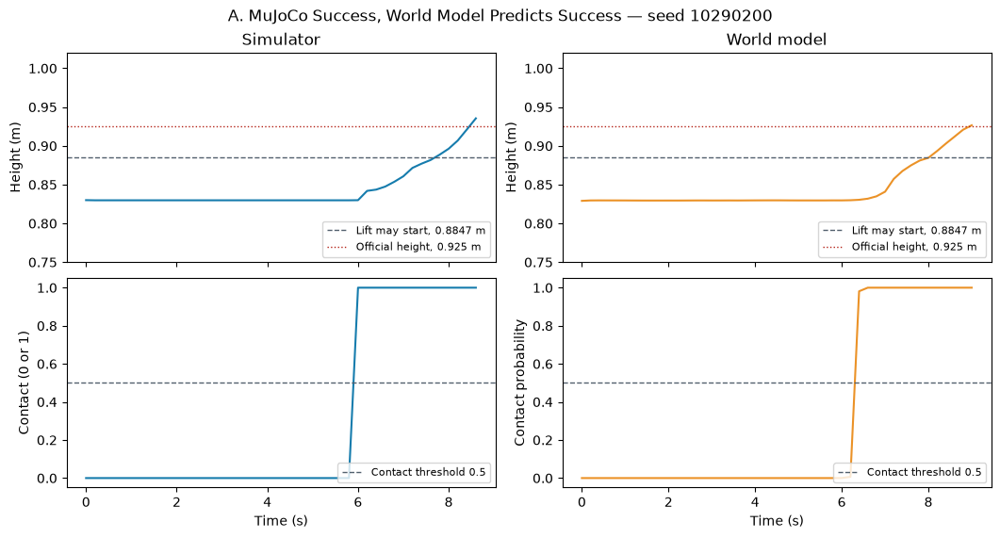

In [3]:
episode = show_case(10290200, "A. MuJoCo Success, World Model Predicts Success — seed 10290200")

**Compare:** Watch when each trajectory first meets both success conditions.

In [4]:
display(Video(str(PACK / "wm_success_animation.mp4"), embed=True, width=1100))
display(HTML("<details><summary>Last saved frame: height and contact</summary><p>These values describe the ending; success can occur at any saved step.</p><table><tr><th>Final simulator height (m)</th><th>Final simulator contact</th><th>Final model height (m)</th><th>Final model contact probability</th></tr><tr><td>" + f"{episode['sim_height'][-1]:.4f}" + "</td><td>" + f"{episode['sim_contact'][-1]:.0f}" + "</td><td>" + f"{episode['model_height'][-1]:.4f}" + "</td><td>" + f"{episode['model_contact'][-1]:.3f}" + "</td></tr></table></details>"))

Final simulator height (m),Final simulator contact,Final model height (m),Final model contact probability
0.9355,1,0.9265,1.000


**Takeaway:** Both succeed: MuJoCo at **8.6 s**, the model at **9.0 s**.

### B. MuJoCo Success, World Model Predicts Failure

Seed **10290212** · **Watch:** Watch for the late lift.

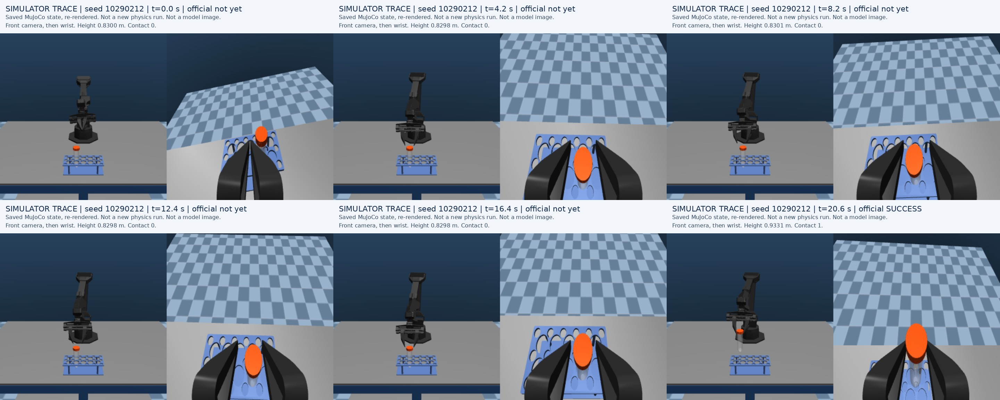

In [5]:
display(Video(str(PACK / "sim_for_wm_failure.mp4"), embed=True, width=1000))
display(Image(filename=str(PACK / "sim_for_wm_failure_timeline.jpg"), width=1100))

**Measure:** MuJoCo meets both conditions at 20.6 s; the model does not.

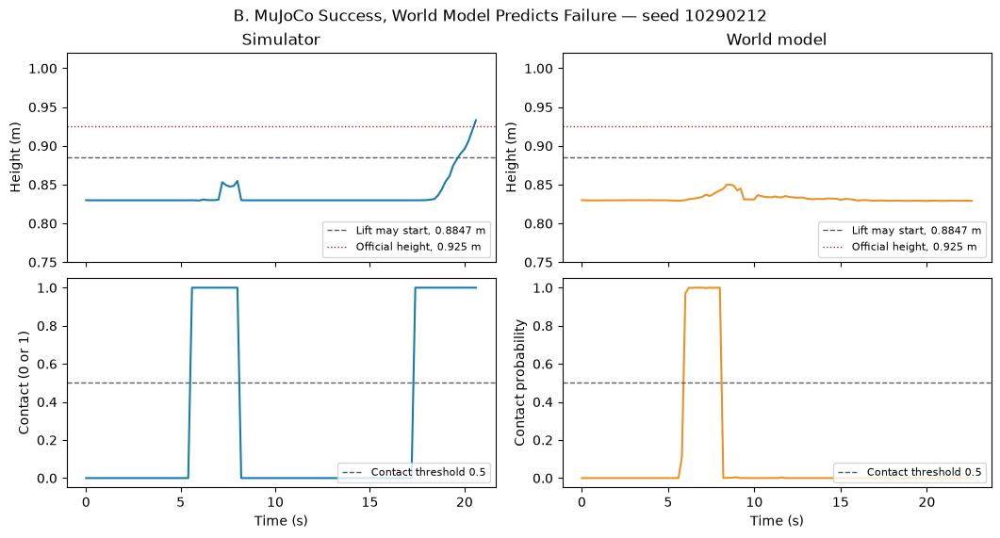

In [6]:
episode = show_case(10290212, "B. MuJoCo Success, World Model Predicts Failure — seed 10290212")

**Compare:** The blue reference lifts, but the orange prediction stays low.

In [7]:
display(Video(str(PACK / "wm_failure_animation.mp4"), embed=True, width=1100))
display(HTML("<details><summary>Last saved frame: height and contact</summary><p>These values describe the ending; success can occur at any saved step.</p><table><tr><th>Final simulator height (m)</th><th>Final simulator contact</th><th>Final model height (m)</th><th>Final model contact probability</th></tr><tr><td>" + f"{episode['sim_height'][-1]:.4f}" + "</td><td>" + f"{episode['sim_contact'][-1]:.0f}" + "</td><td>" + f"{episode['model_height'][-1]:.4f}" + "</td><td>" + f"{episode['model_contact'][-1]:.3f}" + "</td></tr></table></details>"))

Final simulator height (m),Final simulator contact,Final model height (m),Final model contact probability
0.9331,1,0.8291,0.000


**Takeaway:** The model misses an actual MuJoCo success at **20.6 s**.

### C. MuJoCo Failure, World Model Predicts Success

Seed **10290201** · **Watch:** Check whether the tube actually lifts.

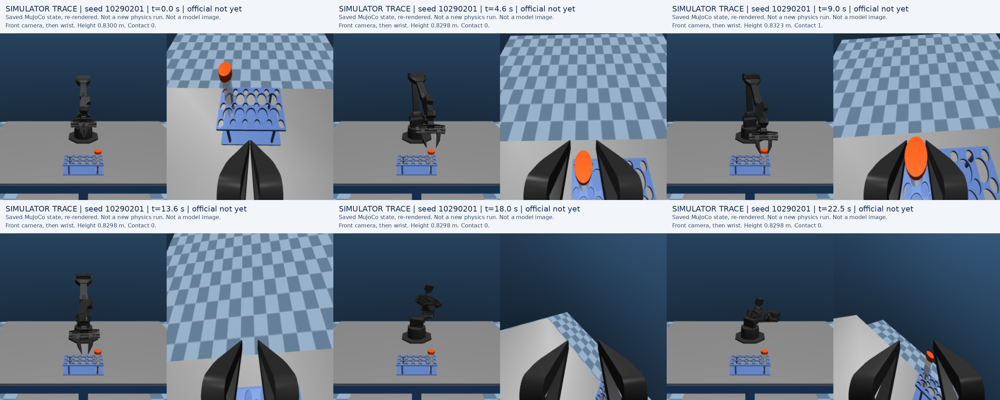

In [8]:
display(Video(str(PACK / "sim_for_model_success.mp4"), embed=True, width=1000))
display(Image(filename=str(PACK / "sim_for_model_success_timeline.jpg"), width=1100))

**Measure:** The saved 9.0 s frame records simulator contact, and the other five displayed frames record contact off. Height stays near 0.83 m, so height and contact are not met together. The model predicts success at **10.0 s**.

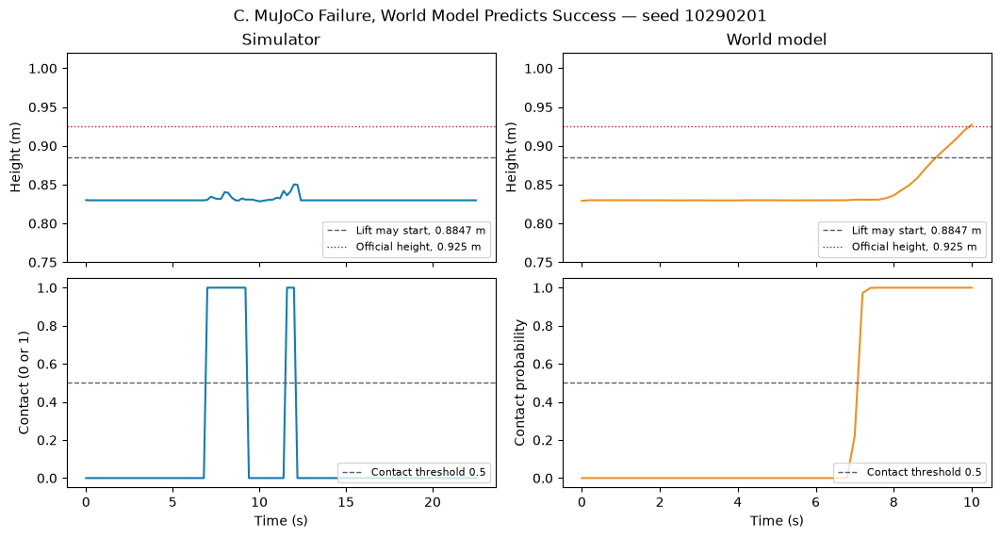

In [9]:
episode = show_case(10290201, "C. MuJoCo Failure, World Model Predicts Success — seed 10290201")

**Compare:** The orange prediction lifts while the blue reference does not.

In [10]:
display(Video(str(PACK / "wm_imagined_success_animation.mp4"), embed=True, width=1100))
display(HTML("<details><summary>Last saved frame: height and contact</summary><p>These values describe the ending; success can occur at any saved step.</p><table><tr><th>Final simulator height (m)</th><th>Final simulator contact</th><th>Final model height (m)</th><th>Final model contact probability</th></tr><tr><td>" + f"{episode['sim_height'][-1]:.4f}" + "</td><td>" + f"{episode['sim_contact'][-1]:.0f}" + "</td><td>" + f"{episode['model_height'][-1]:.4f}" + "</td><td>" + f"{episode['model_contact'][-1]:.3f}" + "</td></tr></table></details>"))

Final simulator height (m),Final simulator contact,Final model height (m),Final model contact probability
0.8298,0,0.9272,1.000


**Takeaway:** The model imagines success at **10.0 s**; that lift never happens in MuJoCo.

### D. MuJoCo Failure, World Model Predicts Failure

Seed **10290298** · **Watch:** Watch the attempt through its ending.

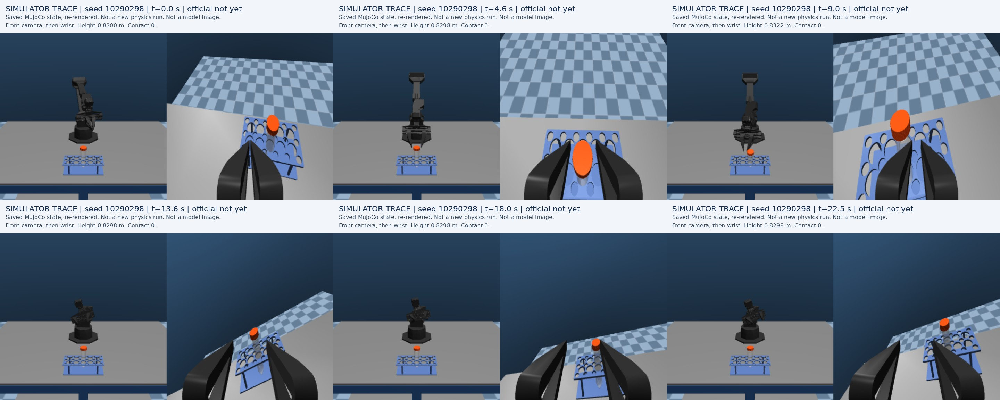

In [11]:
display(Video(str(PACK / "sim_failure.mp4"), embed=True, width=1000))
display(Image(filename=str(PACK / "sim_failure_timeline.jpg"), width=1100))

**Measure:** Neither trajectory meets the height-and-contact condition.

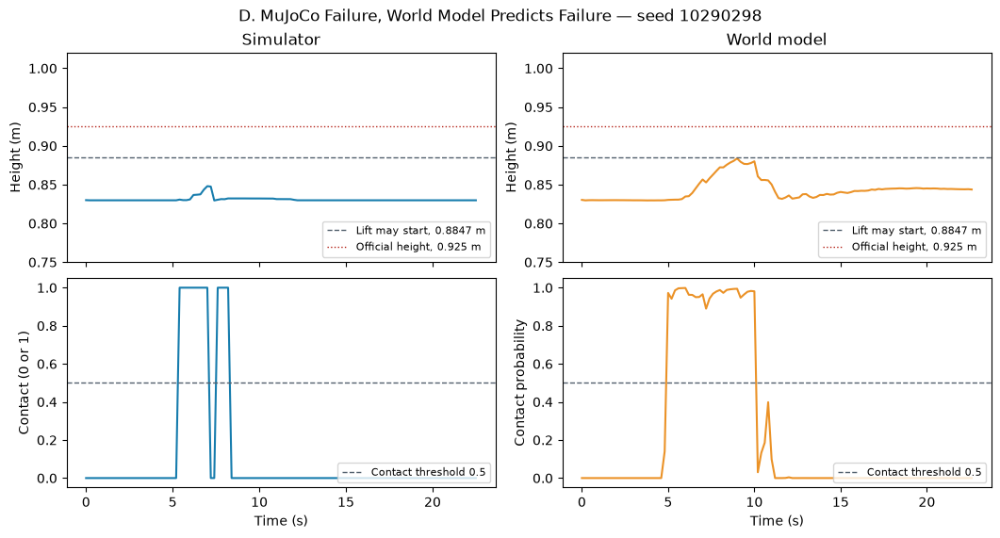

In [12]:
episode = show_case(10290298, "D. MuJoCo Failure, World Model Predicts Failure — seed 10290298")

**Compare:** Both trajectories reach the time limit without a successful lift.

In [13]:
display(Video(str(PACK / "wm_shared_failure_animation.mp4"), embed=True, width=1100))
display(HTML("<details><summary>Last saved frame: height and contact</summary><p>These values describe the ending; success can occur at any saved step.</p><table><tr><th>Final simulator height (m)</th><th>Final simulator contact</th><th>Final model height (m)</th><th>Final model contact probability</th></tr><tr><td>" + f"{episode['sim_height'][-1]:.4f}" + "</td><td>" + f"{episode['sim_contact'][-1]:.0f}" + "</td><td>" + f"{episode['model_height'][-1]:.4f}" + "</td><td>" + f"{episode['model_contact'][-1]:.3f}" + "</td></tr></table></details>"))

Final simulator height (m),Final simulator contact,Final model height (m),Final model contact probability
0.8298,0,0.8437,0.000


**Takeaway:** Both fail; this is the **only shared failure** among the 100 starts.

## 4. What happened across all 100 starts?

Place each case in the matching cell. **Read across for actual successes, down for predicted successes, and add the two green cells for agreement.**

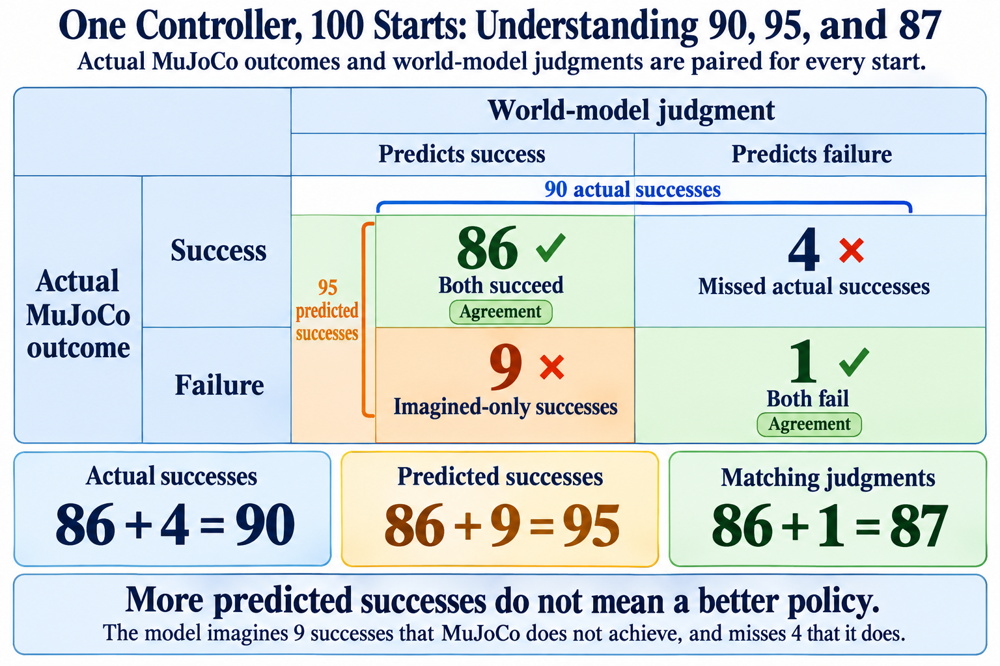

**90 actual successes, 95 predicted successes, 87 matching judgments.** The model calls success more often: 9 imagined-only lifts and 4 missed actual lifts. **95 is neither a higher policy score nor a more accurate evaluation.**

In [14]:
sim = np.array([r['simulator'] for r in rows], dtype=bool)
wm = np.array([r['world_model'] for r in rows], dtype=bool)
counts = [int((sim & wm).sum()), int((sim & ~wm).sum()), int((~sim & wm).sum()), int((~sim & ~wm).sum())]
assert counts == [86, 4, 9, 1]
assert int(sim.sum()) == 90 and int(wm.sum()) == 95 and int((sim == wm).sum()) == 87
print("Saved-label check passed: 90 actual successes, 95 predicted successes, 87 agreements.")

Saved-label check passed: 90 actual successes, 95 predicted successes, 87 agreements.


## 5. What did we learn?

| STAR | The story |
|---|---|
| Situation | Stage 3 showed this latent comparison on PickCube. This stage asks it for test-tube grasping. |
| Task | Can the model anticipate the same frozen controller's MuJoCo outcomes? |
| Action | Inspect matched feedback loops, four paired cases, and all 100 saved labels. |
| Result | On this frozen controller and these 100 starts: **90/100** actual MuJoCo successes and **95/100** model success calls. **87/100** labels match (86 both succeed, 1 both fail). The other starts are **9** imagined-only lifts and **4** missed actual lifts. 90/100 and 95/100 are success counts; 87/100 is agreement. **95 is not a higher policy score or a more accurate evaluation.** |

The success counts are close, and most starts receive the same label. Nine imagined lifts and four missed lifts remain, so the world model is not treated as equivalent to MuJoCo. This stage has carried the paired evaluation onto the tube task. Removing those 13 disagreements is not a prerequisite for what comes next.

The next stage studies policy improvement with World-Gymnast in the world model, then checks the controller in MuJoCo before and after that optimization. **This notebook evaluates the current controller; it does not improve it.** These are simulation results, not physical-robot validation. The Stage 2 image-loop result remains 0/10.

## Appendix: optional details and evidence

<details>
<summary>Frozen controller, success rules, and separate results</summary>

- Policy: `dense50_10000.pt`.
- SHA256: `9e6fca7e3bb15b4dee2dcb8ce15b68d324370bd6b8eddcbe9da5886a31f0f2a1`.
- The lift can activate once at height **>= 0.8847 m** with contact. Shoulder angular velocity is **-0.0686 rad/s** and elbow angular velocity is **-0.0933 rad/s**. The lift locks for **50 control steps**, unless contact is lost.
- The policy predicts a **50 x 7** action sequence; execution and dynamics use **10 x 7** packets. One packet covers **0.2 s**.
- Official success requires **height > 0.925 m and contact at the same step**. Model contact uses probability **>= 0.5**. The lower lift-trigger height is not success; success need not persist throughout the episode.
- The separate **180/200** lift result uses another seed set and remains unchanged. It is not pooled with these 100 starts.

</details>

<details>
<summary>How the saved media and checks work</summary>

The published pack is `media/stage4/`. The same saved files are `teaching/media/tube_closed_loop/` in the working copy. `summary.json` holds the 100 paired labels; `cases/` holds the four displayed trajectories. Simulator videos were rendered from saved MuJoCo state snapshots; playing them does not run physics. Model animations display saved numerical predictions, not generated camera frames. Video time is control time, not compute time.

The cell below verifies every original `manifest.json` entry, the smallest seed in each group, and exact equality of each trace's `pred` with the saved model height and contact. The four new overview/result illustrations are presentation assets outside the original experiment manifest.

Run this notebook from `teaching/` in the existing notebook environment to display the saved media and redraw curves, then export to HTML. Code inputs are collapsed in the notebook and omitted from the reading HTML. No training, MuJoCo execution, new scoring, or video rendering is needed.

</details>

<details>
<summary>Earlier explanatory diagrams (optional reference)</summary>

These original diagrams are retained for reference. Read the four-outcome cards as outcome categories; a shared label does not establish the same failure mechanism for every start.

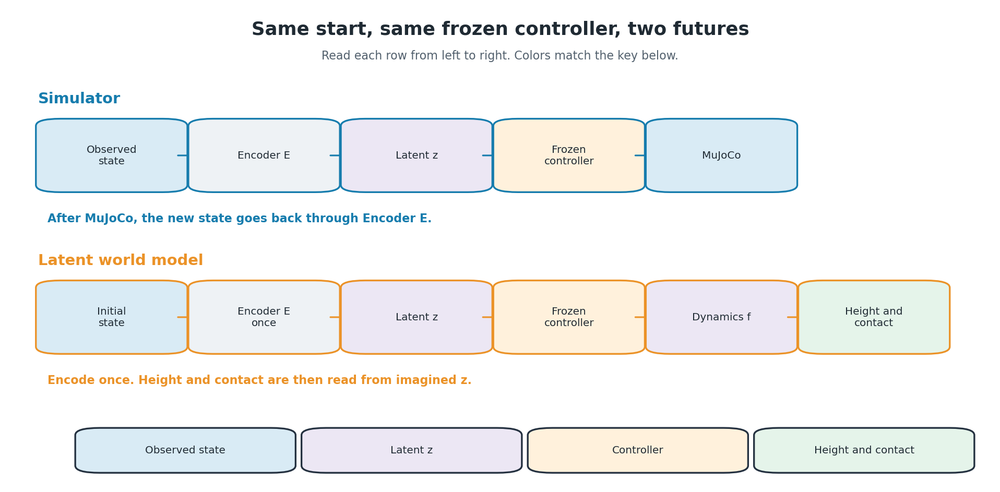

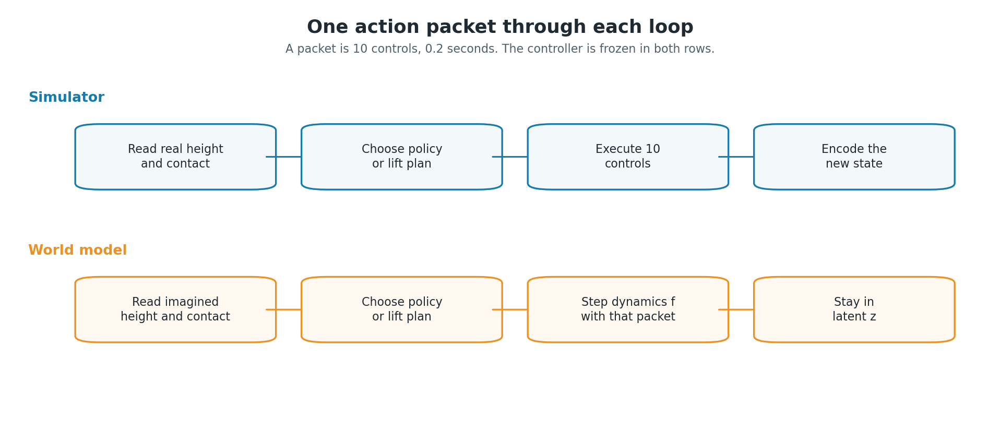

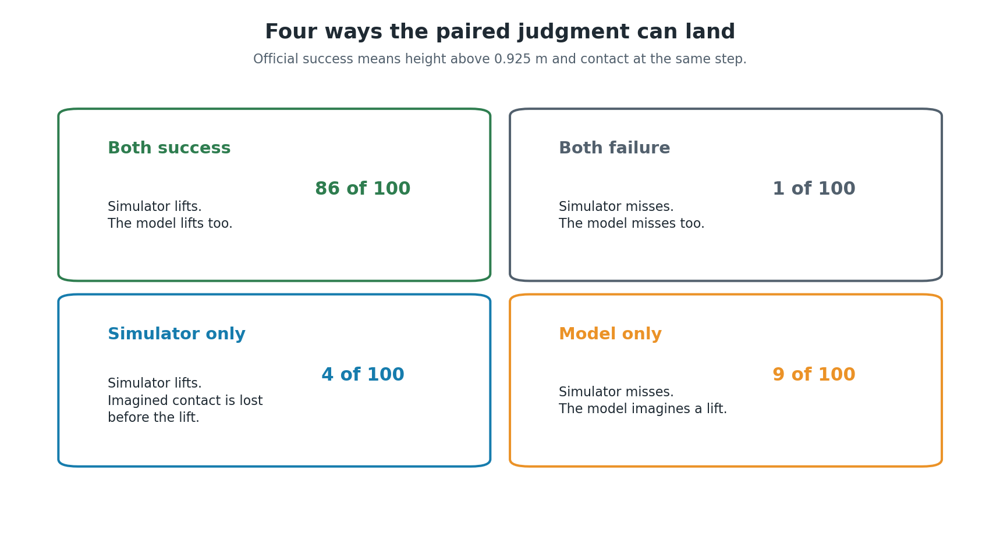

</details>

In [15]:
assert len(rows) == 100 and sorted(r['seed'] for r in rows) == list(range(10290200, 10290300))
manifest = json.loads((PACK / "manifest.json").read_text(encoding="utf-8"))
for name, digest in manifest.items():
    assert hashlib.sha256((PACK / name).read_bytes()).hexdigest() == digest, name
groups = {
    "both_success": [r["seed"] for r in rows if r["simulator"] and r["world_model"]],
    "both_failure": [r["seed"] for r in rows if (not r["simulator"]) and (not r["world_model"])],
    "simulator_only": [r["seed"] for r in rows if r["simulator"] and (not r["world_model"])],
    "model_only": [r["seed"] for r in rows if (not r["simulator"]) and r["world_model"]],
}
for key, seeds in groups.items():
    assert summary["cases"][key] == min(seeds)
assert summary["policy_sha256"] == "9e6fca7e3bb15b4dee2dcb8ce15b68d324370bd6b8eddcbe9da5886a31f0f2a1"
for seed in summary["cases"].values():
    trace = np.load(PACK / f"{seed}_trace.npz")
    case = np.load(PACK / "cases" / f"{seed}.npz")
    assert np.array_equal(trace["pred"][:, 0], case["model_height"])
    assert np.array_equal(trace["pred"][:, 1], case["model_contact"])
print(f"Checked {len(manifest)} files, four case seeds, and four replayed predictions.")

Checked 25 files, four case seeds, and four replayed predictions.
